# Praktikum 2: Memperagakan Penuaan Model dan Training–Serving Skew
**Machine Learning Operations (SD25-40001)**
Dataset: Kredit Sumatera (Seed 42)
Tujuan:
1. Membuktikan secara empiris bahwa kinerja model menurun seiring waktu tanpa perubahan kode.
2. Memperagakan training–serving skew dan mengukur dampaknya pada keputusan bisnis riil.
3. Menjelaskan mengapa kedua kegagalan tersebut tidak terdeteksi oleh pengujian perangkat lunak tradisional.

## Langkah 1: Mengukur Penuaan Model Bulan demi Bulan (2024)

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

if not Path('data/raw/kredit_sumatera.csv').exists() and Path('../data/raw/kredit_sumatera.csv').exists():
    os.chdir('..')

df = pd.read_csv('data/raw/kredit_sumatera.csv')
df['rasio_angsuran'] = df.angsuran_bulanan / df.penghasilan_bulanan
num = ['usia', 'tanggungan', 'lama_usaha_tahun', 'penghasilan_bulanan',
       'ragam_penghasilan', 'plafon_diajukan', 'tenor_bulan', 'bunga_tahunan',
       'rasio_angsuran', 'rata_saldo_90h', 'jumlah_tunggakan_12b']
X = df[num].join(pd.get_dummies(df[['segmen', 'wilayah', 'kanal']]))
y = df.gagal_bayar

# Latih model sekali pada data 2022-2023
latih = df.periode <= '2023-12'
model = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06,
                                       max_iter=250, random_state=42).fit(X[latih], y[latih])

# Evaluasi kinerja bulan demi bulan sepanjang 2024
baris = []
for periode in sorted(df.loc[df.periode > '2023-12', 'periode'].unique()):
    m = df.periode == periode
    baris.append({
        'periode': periode,
        'n': int(m.sum()),
        'auc': roc_auc_score(y[m], model.predict_proba(X[m])[:, 1]),
        'laju_gagal': float(y[m].mean())
    })
hasil = pd.DataFrame(baris)
print(hasil.round(4).to_string(index=False))

periode   n    auc  laju_gagal
2024-01 900 0.7881      0.0911
2024-02 900 0.7183      0.0789
2024-03 900 0.7440      0.0778
2024-04 900 0.7744      0.0789
2024-05 900 0.8122      0.0733
2024-06 900 0.7681      0.1056
2024-07 900 0.7798      0.1100
2024-08 900 0.7560      0.1122
2024-09 900 0.7726      0.1244
2024-10 900 0.7902      0.0978
2024-11 900 0.7525      0.1044
2024-12 900 0.7923      0.1222


### Visualisasi Penuaan Model (ROC-AUC vs Periode)

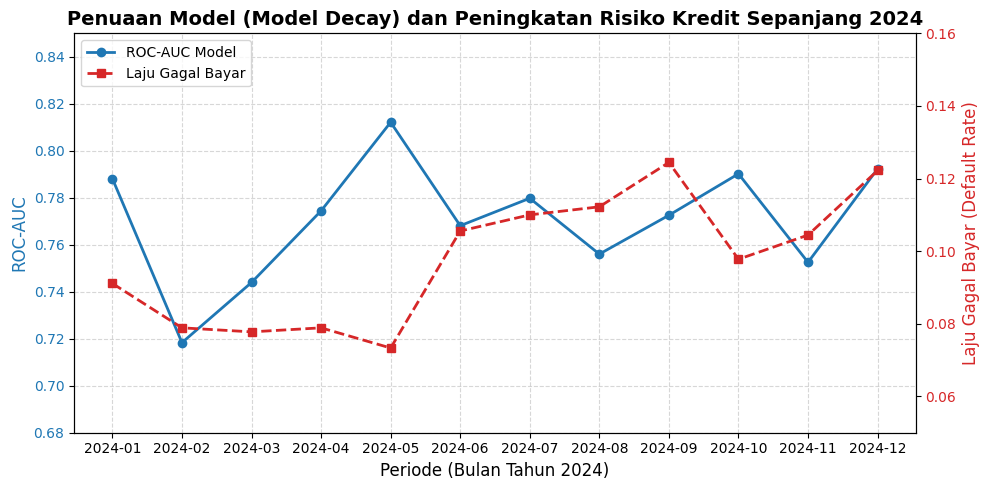

In [2]:
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Periode (Bulan Tahun 2024)', fontsize=12)
ax1.set_ylabel('ROC-AUC', color=color, fontsize=12)
l1 = ax1.plot(hasil['periode'], hasil['auc'], marker='o', color=color, linewidth=2, label='ROC-AUC Model')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.68, 0.85)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Laju Gagal Bayar (Default Rate)', color=color, fontsize=12)
l2 = ax2.plot(hasil['periode'], hasil['laju_gagal'], marker='s', linestyle='--', color=color, linewidth=2, label='Laju Gagal Bayar')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0.05, 0.16)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Penuaan Model (Model Decay) dan Peningkatan Risiko Kredit Sepanjang 2024', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Langkah 2: Menelusuri Penyebabnya

In [3]:
# (a) Apakah komposisi populasi bergeser?
awal = df[df.periode <= '2022-06']
akhir = df[df.periode >= '2024-07']
print('Pergeseran Komposisi Segmen (Awal vs Akhir):')
print(pd.DataFrame({
    'awal': awal.segmen.value_counts(normalize=True),
    'akhir': akhir.segmen.value_counts(normalize=True),
    'perubahan': akhir.segmen.value_counts(normalize=True) - awal.segmen.value_counts(normalize=True)
}).round(4))

Pergeseran Komposisi Segmen (Awal vs Akhir):
                    awal   akhir  perubahan
segmen                                     
pegawai_tetap     0.4141  0.3111    -0.1030
wiraswasta        0.2506  0.2322    -0.0183
pedagang_musiman  0.1406  0.1787     0.0381
petani            0.1293  0.1674     0.0381
nelayan           0.0656  0.1106     0.0450


In [4]:
# (b) Apakah kinerja memburuk merata, atau terpusat pada segmen tertentu?
uji = df.periode > '2024-06'
skor = model.predict_proba(X[uji])[:, 1]
print('Kinerja per Segmen pada Data Uji Out-of-Time (2024-H2):')
for seg, g in df[uji].groupby('segmen'):
    idx = g.index
    s = pd.Series(skor, index=df[uji].index)
    print(f'{seg:<18} n={len(g):5d} auc={roc_auc_score(y.loc[idx], s.loc[idx]):.3f} laju_gagal={y.loc[idx].mean():.3%}')

Kinerja per Segmen pada Data Uji Out-of-Time (2024-H2):
nelayan            n=  597 auc=0.794 laju_gagal=14.238%
pedagang_musiman   n=  965 auc=0.766 laju_gagal=13.679%
pegawai_tetap      n= 1680 auc=0.784 laju_gagal=7.738%
petani             n=  904 auc=0.705 laju_gagal=13.606%
wiraswasta         n= 1254 auc=0.773 laju_gagal=10.686%


## Langkah 3 & 4: Memperagakan Training–Serving Skew dan Membaca Dampaknya

In [5]:
from src import data as D

CFG = {'data': {'mentah': 'data/raw/kredit_sumatera.csv', 'batas_latih': '2023-12', 'batas_validasi': '2024-06'}}
KOLOM = ['usia', 'tanggungan', 'penghasilan_bulanan', 'ragam_penghasilan',
         'plafon_diajukan', 'tenor_bulan', 'rata_saldo_90h',
         'jumlah_tunggakan_12b', 'rasio_angsuran']

df_raw = D.muat(CFG['data']['mentah'])
latih_df, _, uji_df = D.bagi_waktu(df_raw, CFG['data']['batas_latih'], CFG['data']['batas_validasi'])

# 1. Pipeline Pelatihan: nilai hilang diisi MEDIAN data latih
d_latih = latih_df.copy()
d_latih['rasio_angsuran'] = d_latih['angsuran_bulanan'] / d_latih['penghasilan_bulanan']
X_latih = d_latih[KOLOM].fillna(d_latih[KOLOM].median())
median_latih = X_latih.median()

m_skew = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06, max_iter=250, random_state=42)
m_skew.fit(X_latih, latih_df['gagal_bayar'])

# 2. Penyajian KONSISTEN: memakai median latih
d_uji = uji_df.copy()
d_uji['rasio_angsuran'] = d_uji['angsuran_bulanan'] / d_uji['penghasilan_bulanan']
X_benar = d_uji[KOLOM].fillna(median_latih)

# 3. Penyajian MENYIMPANG (SKEW): tim layanan mengisi nol
X_salah = d_uji[KOLOM].fillna(0)

y_uji = uji_df['gagal_bayar'].values
s_benar = m_skew.predict_proba(X_benar)[:, 1]
s_salah = m_skew.predict_proba(X_salah)[:, 1]

auc_benar = roc_auc_score(y_uji, s_benar)
auc_salah = roc_auc_score(y_uji, s_salah)

ambang = 0.085
balik = ((s_benar >= ambang) != (s_salah >= ambang))
kena = uji_df[['rata_saldo_90h', 'lama_usaha_tahun']].isna().any(axis=1).values

print(f'Baris uji dengan setidaknya satu nilai hilang : {kena.sum()} dari {len(uji_df)} ({kena.mean():.1%})')
print(f'AUC dengan definisi fitur KONSISTEN           : {auc_benar:.4f}')
print(f'AUC dengan definisi fitur MENYIMPANG          : {auc_salah:.4f}')
print(f'Selisih                                       : {auc_benar - auc_salah:+.4f}')
print(f'\nKeputusan yang BERUBAH akibat skew          : {balik.sum()} ({balik.mean():.2%} dari seluruh permohonan)')
print(f'AUC pada baris yang terdampak — konsisten     : {roc_auc_score(y_uji[kena], s_benar[kena]):.4f}')
print(f'AUC pada baris yang terdampak — menyimpang    : {roc_auc_score(y_uji[kena], s_salah[kena]):.4f}')


Baris uji dengan setidaknya satu nilai hilang : 289 dari 5400 (5.4%)
AUC dengan definisi fitur KONSISTEN           : 0.7711
AUC dengan definisi fitur MENYIMPANG          : 0.7683
Selisih                                       : +0.0028

Keputusan yang BERUBAH akibat skew          : 66 (1.22% dari seluruh permohonan)
AUC pada baris yang terdampak — konsisten     : 0.7982
AUC pada baris yang terdampak — menyimpang    : 0.7644
